## Imports and plot settings

- `subprocess`: launches the `ftw` command-line tool from Python.
- `geopandas`: reads and handles the vector field polygons.
- `rasterio`: reads the GeoTIFF imagery. `plotting_extent` converts the raster's georeferencing into the coordinate bounds that matplotlib needs.
- `plt.rcParams.update(...)`: sets figure defaults only. Saved figures are 900 dpi with tight margins, and all text is 9 pt, which suits a paper or poster. It has no effect on the analysis.

In [7]:
import os
import sys
import subprocess
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

plt.rcParams.update({
    'savefig.dpi':900,
    'savefig.bbox':'tight',
    'savefig.pad_inches':0.02,
    'font.size':9,
    'axes.labelsize':9,
    'axes.titlesize':9,
    'xtick.labelsize':9,
    'ytick.labelsize':9,
    'legend.fontsize':9,
    'figure.titlesize':9,
    'xtick.minor.visible':False,
    'ytick.minor.visible':False})

## Configuration

All the settings you may want to change are here.

- `PROJECTDIR`: working directory under `$SCRATCH` (HPC scratch storage). The notebook fails if `SCRATCH` isn't set.
- `YEAR`: the imagery year the model runs on.
- `MODEL`: the checkpoint name. `FTW_PRUE_EFNET_B5` is the PRUE U-Net with an EfficientNet-B5 encoder, the improved boundary model from your notes.
- `BBOX`: `(min_lon, min_lat, max_lon, max_lat)` in degrees. This is roughly a 3.7 × 5.5 km tile in Austria.
- `GPU`: device index used for inference.
- `OVERWRITE`: if `True`, the next cell reruns inference even when outputs exist.

Derived paths:
- `IMAGERY`: the Sentinel-2 input stack.
- `PREDICTION`: the raw model output raster.
- `POLYGONS`: the vectorized fields.
- `FIGURE`: the output plot.
- `FTW`: the path to the `ftw` executable, assumed to sit in the same `bin/` as the active Python (i.e., installed in this environment).

In [8]:
PROJECTDIR = os.path.join(os.environ['SCRATCH'],'ftw')
YEAR       = 2024
MODEL      = 'FTW_PRUE_EFNET_B5'
BBOX       = (13.0,48.0,13.05,48.05)
GPU        = 0
OVERWRITE  = False

OUTPUTDIR  = os.path.join(PROJECTDIR,'outputs',f'austria_{YEAR}')
IMAGERY    = os.path.join(OUTPUTDIR,'inference_data.tif')
PREDICTION = os.path.join(OUTPUTDIR,'inference_output.tif')
POLYGONS   = os.path.join(OUTPUTDIR,'polygons.parquet')
FIGURE     = os.path.join(OUTPUTDIR,'field_boundaries.png')
FTW        = os.path.join(os.path.dirname(sys.executable),'ftw')

os.makedirs(OUTPUTDIR,exist_ok=True)

## Run FTW inference

Skips everything if all three output files already exist (unless `OVERWRITE=True`).

Otherwise it runs `ftw inference all`, which chains three steps:
1. **Download**: fetches Sentinel-2 imagery for the bbox and year.
2. **Run**: applies the model to produce per-pixel predictions (field interior and boundary).
3. **Polygonize**: converts the prediction raster into vector field polygons.

Outputs: `inference_data.tif`, `inference_output.tif`, `polygons.parquet`.

`subprocess.Popen` streams the CLI's log live into the notebook. The cell raises an error if the command exits nonzero.

Note: the command always passes `--overwrite`, so `OVERWRITE` only controls whether the command runs at all, not what the CLI does once it runs.

In [9]:
if OVERWRITE or not all(os.path.isfile(f) for f in [IMAGERY,PREDICTION,POLYGONS]):
    command = [
        FTW,'inference','all',
        '--bbox',','.join(map(str,BBOX)),
        '--year',str(YEAR),
        '--out',OUTPUTDIR,
        '--model',MODEL,
        '--gpu',str(GPU),
        '--overwrite']

    with subprocess.Popen(
        command,cwd=PROJECTDIR,
        stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
        text=True,bufsize=1,
    ) as process:
        for line in process.stdout:
            print(line,end='',flush=True)
        returncode = process.wait()

    if returncode != 0:
        raise subprocess.CalledProcessError(returncode,command)

## Cell 3: Load imagery and polygons

**Imagery**
- Reads bands 1–3 as float and converts nodata pixels to NaN.
- These are assumed to be R, G, B. Check `src.count` and `src.descriptions`, because FTW inputs stack multiple dates (e.g., planting and harvest windows) and the order determines what you're seeing.
- Moves bands to the last axis, `(H, W, 3)`, as matplotlib expects.
- Applies a per-band 2nd–98th percentile contrast stretch and clips to [0, 1], so the image looks reasonable regardless of reflectance range.
- Saves `extent` and `crs` so the polygons can be aligned to the image.

**Polygons**
- Reads `polygons.parquet` and reprojects it to the imagery's CRS (a metric UTM zone here).
- Columns: `id`, `metrics:area` (m²), `metrics:perimeter` (m), and `geometry`.
- 94 fields were predicted in this tile.

This GeoDataFrame has the same structure as the global FTW polygons: one row per field, which is what you'll attach embedding statistics and crop labels to.

In [10]:
with rasterio.open(IMAGERY) as src:
    rgb = src.read([1,2,3],out_dtype='float32',masked=True).filled(np.nan)
    extent = plotting_extent(src)
    crs = src.crs

rgb = np.moveaxis(rgb,0,-1)
lower = np.nanpercentile(rgb,2,axis=(0,1))
upper = np.nanpercentile(rgb,98,axis=(0,1))
rgb = np.clip((rgb-lower)/np.maximum(upper-lower,1e-6),0,1)

fields = gpd.read_parquet(POLYGONS).to_crs(crs)

print(f'{len(fields):,} predicted fields')
fields.head()

94 predicted fields


,id,metrics:area,metrics:perimeter,geometry
0,1,1500.0,220.0,"POLYGON ((800850 5329800, 800850 5329780, 8008..."
1,2,2800.0,260.0,"POLYGON ((798360 5329800, 798360 5329790, 7983..."
2,3,2200.0,220.0,"POLYGON ((799070 5329800, 799070 5329790, 7990..."
3,4,16400.0,800.0,"POLYGON ((801580 5329800, 801580 5329780, 8015..."
4,5,9300.0,800.0,"POLYGON ((800570 5329790, 800570 5329780, 8005..."


## Plot boundaries over imagery

- Draws the stretched RGB image using the georeferenced `extent`.
- Overlays each polygon's outline (`.boundary`) in cyan.
- Hides the axes, adds a title, and saves the figure to `FIGURE`.

Use this as a visual sanity check. The outlines should follow visible field edges. Typical errors are merged neighbouring fields, split fields, and missed small parcels.

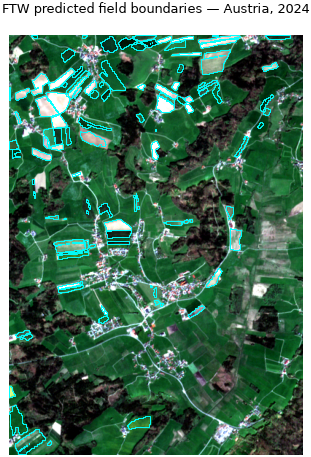

In [12]:
fig,ax = plt.subplots()
ax.imshow(rgb,extent=extent)

if not fields.empty:
    fields.boundary.plot(ax=ax,color='cyan',linewidth=0.7)

ax.set_title(f'FTW predicted field boundaries — Austria, {YEAR}')
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIGURE)
plt.show()